In [1]:
# Cell 1: 加载 Phase 1 SAE + 注释 + AnnData / Load Phase 1 SAE + Annotations + AnnData
import os
import pickle
import json
import numpy as np
import pandas as pd
import scanpy as sc
from collections import Counter

SCRIPT_DIR = "/Users/elvainyu/Desktop/申请与学习/暑研和实习/暑研/‼️2026暑研资料/Computational Biology/Papers & Datas/SAE training/sae_code"
OUT_DIR    = os.path.join(SCRIPT_DIR, "20260527_Progenitor_Commitment_Outputs")
os.makedirs(OUT_DIR, exist_ok=True)

# === Load Phase 1 SAE activation matrix (161604, 2048) ===
print("[1/3] Loading Phase 1 SAE results (sae_results_all.pkl)...")
with open(os.path.join(SCRIPT_DIR, "sae_results_all.pkl"), "rb") as f:
    data = pickle.load(f)
raw_feats = data[1]
X_sae = raw_feats.detach().cpu().numpy() if hasattr(raw_feats, "detach") else np.array(raw_feats)
print(f"      X_sae shape: {X_sae.shape}  (expected 161604 x 2048)")

# === Load Session 8 cluster assignments (209 active features -> 8 clusters) ===
print("[2/3] Loading Session 8 cluster assignments (task6_cluster_assignments.csv)...")
cluster_df = pd.read_csv(os.path.join(SCRIPT_DIR, "task6_cluster_assignments.csv"))
print(f"      cluster_df shape: {cluster_df.shape}")
print(f"      Columns: {list(cluster_df.columns)}")
print(f"      Cluster distribution:")
for cid, n in cluster_df["cluster"].value_counts().sort_index().items():
    print(f"        Cluster {cid}: {n} features")

# === Load AnnData for CellType labels ===
print("[3/3] Loading BoneMarrowMap_Unsorted_scVI.h5ad...")
adata = sc.read_h5ad(os.path.join(SCRIPT_DIR, "../../Papers' Dataset/BoneMarrowMap_Unsorted_scVI.h5ad"))
print(f"      adata shape: {adata.shape}  (expected 161604 x 4000)")

cell_types = adata.obs["CellType"].values
print(f"      Unique cell types: {len(set(cell_types))}")

print(f"\nAll inputs loaded. Ready for Cell 2 (progenitor filtering).")

/opt/miniconda3/envs/scanpy-env/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


[1/3] Loading Phase 1 SAE results (sae_results_all.pkl)...
      X_sae shape: (161604, 2048)  (expected 161604 x 2048)
[2/3] Loading Session 8 cluster assignments (task6_cluster_assignments.csv)...
      cluster_df shape: (209, 3)
      Columns: ['feature_id', 'programme_name', 'cluster']
      Cluster distribution:
        Cluster 1: 9 features
        Cluster 2: 41 features
        Cluster 3: 60 features
        Cluster 4: 17 features
        Cluster 5: 22 features
        Cluster 6: 17 features
        Cluster 7: 7 features
        Cluster 8: 36 features
[3/3] Loading BoneMarrowMap_Unsorted_scVI.h5ad...
      adata shape: (161604, 4000)  (expected 161604 x 4000)
      Unique cell types: 55

All inputs loaded. Ready for Cell 2 (progenitor filtering).


In [2]:
# Cell 2: 定义祖细胞 + 成熟参照 + 筛子集 / Define Progenitor + Mature Reference + Filter
# 按发育阶段排序，构成"发育脊柱" / Ordered by developmental stage

DEVELOPMENTAL_SPINE = [
    # ========== Stage 0: Stem cell ==========
    ("HSC",                       "S0_Stem"),
    # ========== Stage 1: Multipotent progenitors ==========
    ("LMPP",                      "S1_Multipotent"),
    ("MPP-MyLy",                  "S1_Multipotent"),
    ("MPP-MkEry",                 "S1_Multipotent"),
    ("Cycling Progenitor",        "S1_Multipotent"),
    # ========== Stage 2: Oligopotent (lineage-committed but not specified) ==========
    ("MLP",                       "S2_Oligopotent_Lymphoid"),
    ("MLP-II",                    "S2_Oligopotent_Lymphoid"),
    ("CLP",                       "S2_Oligopotent_Lymphoid"),
    ("MEP",                       "S2_Oligopotent_MkEry"),
    ("Early GMP",                 "S2_Oligopotent_Myeloid"),
    ("GMP-Cycle",                 "S2_Oligopotent_Myeloid"),
    # ========== Stage 3: Lineage-restricted progenitors ==========
    ("Pre-ProB",                  "S3_Restricted_B"),
    ("Pro-B Cycling",             "S3_Restricted_B"),
    ("Pro-B VDJ",                 "S3_Restricted_B"),
    ("Large Pre-B",               "S3_Restricted_B"),
    ("Small Pre-B",               "S3_Restricted_B"),
    ("BFU-E",                     "S3_Restricted_Erythroid"),
    ("CFU-E",                     "S3_Restricted_Erythroid"),
    ("Megakaryocyte Precursor",   "S3_Restricted_Mk"),
    ("GMP-Mono",                  "S3_Restricted_Mono"),
    ("Early ProMono",             "S3_Restricted_Mono"),
    ("Late ProMono",              "S3_Restricted_Mono"),
    ("GMP-Neut",                  "S3_Restricted_Neut"),
    ("EoBasoMast Precursor",      "S3_Restricted_EoBasoMast"),
    ("Pre-cDC",                   "S3_Restricted_DC"),
    ("ASDC",                      "S3_Restricted_DC"),
    ("Pre-pDC",                   "S3_Restricted_DC"),
    ("Pre-pDC Cycling",           "S3_Restricted_DC"),
    # ========== Stage 4: Mature reference (endpoint) ==========
    ("Immature B",                "S4_Mature_B"),
    ("Mature B",                  "S4_Mature_B"),
    ("Plasma Cell",               "S4_Mature_B"),
    ("Pro-Erythroblast",          "S4_Mature_Erythroid"),
    ("Basophilic Erythroblast",   "S4_Mature_Erythroid"),
    ("Polychromatic Erythroblast","S4_Mature_Erythroid"),
    ("Orthochromatic Erythroblast","S4_Mature_Erythroid"),
    ("Megakaryocyte",             "S4_Mature_Mk"),
    ("CD14 Mono",                 "S4_Mature_Mono"),
    ("CD16 Mono",                 "S4_Mature_Mono"),
    ("cDC1",                      "S4_Mature_DC"),
    ("cDC2",                      "S4_Mature_DC"),
    ("pDC",                       "S4_Mature_DC"),
    ("CD4 Naive",                 "S4_Mature_T"),
    ("CD4 Central Memory",        "S4_Mature_T"),
    ("CD4 Effector Memory",       "S4_Mature_T"),
    ("CD4 Regulatory",            "S4_Mature_T"),
    ("CD8 Naive",                 "S4_Mature_T"),
    ("CD8 Central Memory",        "S4_Mature_T"),
    ("CD8 Effector Memory 1",     "S4_Mature_T"),
    ("CD8 Effector Memory 2",     "S4_Mature_T"),
    ("CD8 Tissue Resident Memory","S4_Mature_T"),
    ("T Proliferating",           "S4_Mature_T"),
    ("NK",                        "S4_Mature_NK"),
    ("NK CD56high",               "S4_Mature_NK"),
    ("NK Proliferating",          "S4_Mature_NK"),
]

celltype_to_stage = dict(DEVELOPMENTAL_SPINE)
celltype_order    = [ct for ct, _ in DEVELOPMENTAL_SPINE]

# Build mask: cells matching any developmental spine entry
mask = np.array([ct in celltype_to_stage for ct in cell_types])
print(f"Cells matching developmental spine: {mask.sum()} / {len(mask)}")

# Per-celltype counts in developmental order
print(f"\nPer-celltype counts (ordered by developmental stage):")
current_stage = None
for ct in celltype_order:
    n = int((cell_types == ct).sum())
    stage = celltype_to_stage[ct]
    if stage != current_stage:
        print(f"\n  === {stage} ===")
        current_stage = stage
    if n > 0:
        print(f"    {ct:<28} n={n:>5}")
    else:
        print(f"    {ct:<28} (not found)")

# Extract subset
subset_indices = np.where(mask)[0]
X_sae_subset   = X_sae[subset_indices]
cell_types_subset = cell_types[subset_indices]
stages_subset = np.array([celltype_to_stage[ct] for ct in cell_types_subset])

print(f"\n--- Subset summary ---")
print(f"  X_sae_subset shape:      {X_sae_subset.shape}")
print(f"  Cells per stage:")
for stage, n in Counter(stages_subset).items():
    print(f"    {stage:<30} {n:>6}")

print(f"\nReady for Cell 3 (feature -> cluster mapping).")

Cells matching developmental spine: 161399 / 161604

Per-celltype counts (ordered by developmental stage):

  === S0_Stem ===
    HSC                          n= 1116

  === S1_Multipotent ===
    LMPP                         n=  715
    MPP-MyLy                     n=  560
    MPP-MkEry                    n=  525
    Cycling Progenitor           n= 1120

  === S2_Oligopotent_Lymphoid ===
    MLP                          n=  260
    MLP-II                       n=  104
    CLP                          n=  316

  === S2_Oligopotent_MkEry ===
    MEP                          n=  578

  === S2_Oligopotent_Myeloid ===
    Early GMP                    n= 1522
    GMP-Cycle                    n=  293

  === S3_Restricted_B ===
    Pre-ProB                     n=  320
    Pro-B Cycling                n=  867
    Pro-B VDJ                    n= 1279
    Large Pre-B                  n= 2499
    Small Pre-B                  n=  759

  === S3_Restricted_Erythroid ===
    BFU-E                    

In [4]:
# Cell 3: Map Clusters to Lineage Destinations
CLUSTER_DESTINATIONS = {
    1: {"destination": "Cross-lineage (ER stress)",          "color": "#888888",
        "name": "ER protein folding cross-lineage"},
    2: {"destination": "B / Plasma cell",                    "color": "#3498DB",
        "name": "Plasma cell Ig secretion"},
    3: {"destination": "Erythroid (early, OXPHOS)",          "color": "#FFEDA0",
        "name": "Early erythroid mitochondrial bioenergetic"},
    4: {"destination": "Erythroid (mid, heme)",              "color": "#FEB24C",
        "name": "Erythroid heme biosynthesis"},
    5: {"destination": "Erythroid (late, Hb)",               "color": "#F03B20",
        "name": "Terminal erythroid hemoglobin synthesis"},
    6: {"destination": "Erythroid (ribosome / proliferating)","color": "#FD8D3C",
        "name": "Erythroid ribosome biogenesis"},
    7: {"destination": "DC / pDC (MHC-II)",                  "color": "#8E44AD",
        "name": "DC MHC-II antigen presentation"},
    8: {"destination": "Pan-progenitor proliferation",       "color": "#27AE60",
        "name": "Multi-lineage progenitor proliferation"},
}

# Build cluster -> feature ID list from cluster_df
cluster_to_features = {}
for cid in sorted(cluster_df["cluster"].unique()):
    fids = cluster_df[cluster_df["cluster"] == cid]["feature_id"].astype(int).tolist()
    cluster_to_features[cid] = fids

print(f"{'Cluster':<8} {'Destination':<42} {'n features':<11} Description")
print("-" * 115)
for cid in sorted(cluster_to_features.keys()):
    info = CLUSTER_DESTINATIONS[cid]
    fids = cluster_to_features[cid]
    print(f"  {cid:<6} {info['destination']:<42} {len(fids):<11} {info['name']}")

print(f"\nTotal annotated features: {sum(len(v) for v in cluster_to_features.values())}")
print(f"\nCOVERAGE NOTE:")
print(f"  Phase 1 SAE primarily covers Erythroid (116/209 = 56%) + B/Plasma (41) + DC (7) + Multi-lineage progenitor (36).")
print(f"  Step A cannot detect Mono / T-NK / Neutrophil commitment.")
print(f"  Step B (projecting all 4 lineage-specific SAE models onto progenitors) is required for full coverage.")
print(f"\nReady for Cell 4 (per-cell cluster activation aggregation).")

Cluster  Destination                                n features  Description
-------------------------------------------------------------------------------------------------------------------
  1      Cross-lineage (ER stress)                  9           ER protein folding cross-lineage
  2      B / Plasma cell                            41          Plasma cell Ig secretion
  3      Erythroid (early, OXPHOS)                  60          Early erythroid mitochondrial bioenergetic
  4      Erythroid (mid, heme)                      17          Erythroid heme biosynthesis
  5      Erythroid (late, Hb)                       22          Terminal erythroid hemoglobin synthesis
  6      Erythroid (ribosome / proliferating)       17          Erythroid ribosome biogenesis
  7      DC / pDC (MHC-II)                          7           DC MHC-II antigen presentation
  8      Pan-progenitor proliferation               36          Multi-lineage progenitor proliferation

Total annotated features: 

In [5]:
# Cell 4: Per-cell Lineage Fingerprint Matrix
# For each cell, compute mean SAE activation per cluster (8 clusters)
# Result: (n_cells, 8) matrix = the "lineage fingerprint"

cluster_order  = sorted(cluster_to_features.keys())
n_clusters     = len(cluster_order)
n_cells_subset = X_sae_subset.shape[0]

fingerprint = np.zeros((n_cells_subset, n_clusters), dtype=np.float32)

for col_idx, cid in enumerate(cluster_order):
    fids = cluster_to_features[cid]
    # Mean activation across all features in this cluster
    fingerprint[:, col_idx] = X_sae_subset[:, fids].mean(axis=1)

print(f"Fingerprint matrix shape: {fingerprint.shape}  ({n_cells_subset} cells x {n_clusters} clusters)")

print(f"\nPer-cluster activation stats across all subset cells:")
print(f"{'Cluster':<8} {'Destination':<42} {'mean':>9} {'std':>9} {'max':>9}")
print("-" * 80)
for col_idx, cid in enumerate(cluster_order):
    info = CLUSTER_DESTINATIONS[cid]
    col_data = fingerprint[:, col_idx]
    print(f"  {cid:<6} {info['destination']:<42} "
          f"{col_data.mean():>9.4f} {col_data.std():>9.4f} {col_data.max():>9.4f}")

# Quick sanity check: cells with highest activation per cluster (should match expected lineages)
print(f"\nSanity check: top-activating cell type per cluster")
for col_idx, cid in enumerate(cluster_order):
    info = CLUSTER_DESTINATIONS[cid]
    top_5_indices = np.argsort(fingerprint[:, col_idx])[::-1][:5]
    top_5_celltypes = [cell_types_subset[i] for i in top_5_indices]
    top_type_counts = Counter(top_5_celltypes).most_common(1)[0]
    print(f"  Cluster {cid} ({info['destination']:<40}): top-5 cells dominated by '{top_type_counts[0]}' ({top_type_counts[1]}/5)")

print(f"\nReady for Cell 5 (aggregate fingerprint by cell type / stage).")

Fingerprint matrix shape: (161399, 8)  (161399 cells x 8 clusters)

Per-cluster activation stats across all subset cells:
Cluster  Destination                                     mean       std       max
--------------------------------------------------------------------------------
  1      Cross-lineage (ER stress)                     0.0006    0.0016    0.1148
  2      B / Plasma cell                               0.0023    0.0143    0.4837
  3      Erythroid (early, OXPHOS)                     0.0001    0.0005    0.1108
  4      Erythroid (mid, heme)                         0.0030    0.0060    0.0789
  5      Erythroid (late, Hb)                          0.0069    0.0239    0.3425
  6      Erythroid (ribosome / proliferating)          0.0056    0.0087    0.1180
  7      DC / pDC (MHC-II)                             0.0056    0.0057    0.3182
  8      Pan-progenitor proliferation                  0.0027    0.0040    0.5800

Sanity check: top-activating cell type per cluster
  Clust

In [6]:
# Cell 5: Aggregate Fingerprint by Cell Type and by Stage
# Group cells by their CellType / developmental stage, compute mean fingerprint per group

# === Per cell type aggregation ===
unique_celltypes_in_order = [ct for ct in celltype_order if ct in set(cell_types_subset)]
n_celltypes = len(unique_celltypes_in_order)

fingerprint_by_celltype = np.zeros((n_celltypes, n_clusters), dtype=np.float32)
celltype_n_cells = np.zeros(n_celltypes, dtype=np.int32)

for row_idx, ct in enumerate(unique_celltypes_in_order):
    mask_ct = (cell_types_subset == ct)
    celltype_n_cells[row_idx] = mask_ct.sum()
    if mask_ct.sum() > 0:
        fingerprint_by_celltype[row_idx] = fingerprint[mask_ct].mean(axis=0)

print(f"fingerprint_by_celltype shape: {fingerprint_by_celltype.shape}  ({n_celltypes} cell types x {n_clusters} clusters)")

# === Per developmental stage aggregation ===
unique_stages_in_order = []
seen_stages = set()
for ct in celltype_order:
    s = celltype_to_stage[ct]
    if s not in seen_stages:
        unique_stages_in_order.append(s)
        seen_stages.add(s)

n_stages = len(unique_stages_in_order)
fingerprint_by_stage = np.zeros((n_stages, n_clusters), dtype=np.float32)
stage_n_cells = np.zeros(n_stages, dtype=np.int32)

for row_idx, stage in enumerate(unique_stages_in_order):
    mask_st = (stages_subset == stage)
    stage_n_cells[row_idx] = mask_st.sum()
    if mask_st.sum() > 0:
        fingerprint_by_stage[row_idx] = fingerprint[mask_st].mean(axis=0)

print(f"fingerprint_by_stage    shape: {fingerprint_by_stage.shape}  ({n_stages} stages x {n_clusters} clusters)")

# === Z-score normalisation (per column / per cluster) for visualization comparability ===
def zscore_columns(matrix):
    mu  = matrix.mean(axis=0, keepdims=True)
    sd  = matrix.std(axis=0, keepdims=True) + 1e-8
    return (matrix - mu) / sd

fingerprint_by_celltype_z = zscore_columns(fingerprint_by_celltype)
fingerprint_by_stage_z    = zscore_columns(fingerprint_by_stage)
print(f"Z-scored versions also computed (each cluster column normalized across rows).")

# === Quick inspection: print stage-level fingerprint table ===
import pandas as pd
print(f"\nPer-stage average fingerprint (raw mean activation):")
stage_df = pd.DataFrame(
    fingerprint_by_stage,
    index=unique_stages_in_order,
    columns=[f"C{cid}:{CLUSTER_DESTINATIONS[cid]['destination'][:18]}" for cid in cluster_order],
)
stage_df.insert(0, "n_cells", stage_n_cells)
print(stage_df.round(4).to_string())

print(f"\nPer-stage z-scored fingerprint (relative pattern across stages):")
stage_df_z = pd.DataFrame(
    fingerprint_by_stage_z,
    index=unique_stages_in_order,
    columns=[f"C{cid}" for cid in cluster_order],
)
print(stage_df_z.round(2).to_string())

print(f"\nReady for Cell 6 (heatmap visualization of fingerprint_by_celltype_z).")

fingerprint_by_celltype shape: (54, 8)  (54 cell types x 8 clusters)
fingerprint_by_stage    shape: (19, 8)  (19 stages x 8 clusters)
Z-scored versions also computed (each cluster column normalized across rows).

Per-stage average fingerprint (raw mean activation):
                          n_cells  C1:Cross-lineage (ER   C2:B / Plasma cell  C3:Erythroid (early,   C4:Erythroid (mid, he  C5:Erythroid (late, H  C6:Erythroid (ribosom  C7:DC / pDC (MHC-II)  C8:Pan-progenitor pro
S0_Stem                      1116                 0.0010              0.0002                 0.0000                 0.0020                 0.0009                 0.0105                0.0079                 0.0020
S1_Multipotent               2920                 0.0017              0.0006                 0.0001                 0.0031                 0.0013                 0.0162                0.0077                 0.0037
S2_Oligopotent_Lymphoid       680                 0.0007              0.0005                

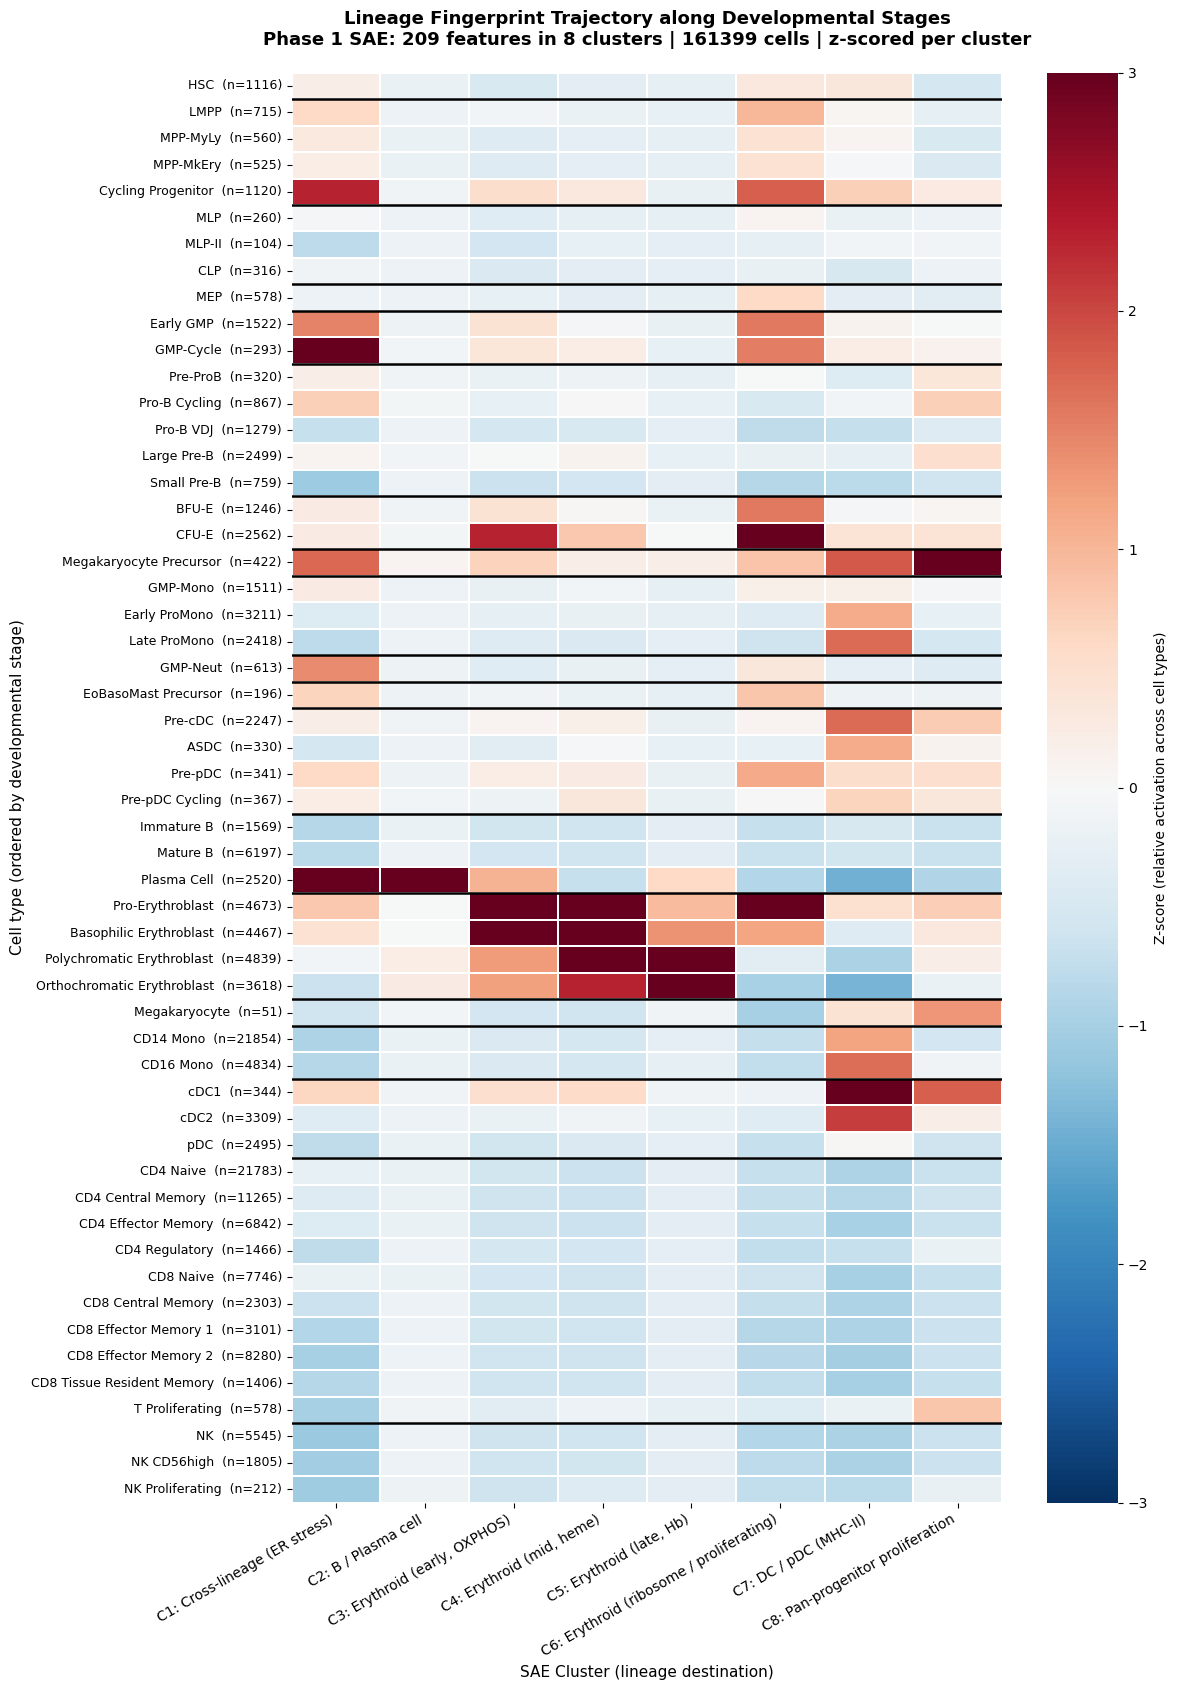


Saved heatmap: /Users/elvainyu/Desktop/申请与学习/暑研和实习/暑研/‼️2026暑研资料/Computational Biology/Papers & Datas/SAE training/sae_code/20260527_Progenitor_Commitment_Outputs/fingerprint_by_celltype_heatmap.png


In [7]:
# Cell 6: Heatmap of Lineage Fingerprints
# Rows = cell types in developmental order, columns = 8 clusters, color = z-score
import matplotlib.pyplot as plt
import seaborn as sns

# Build axis labels
celltype_labels = [f"{ct}  (n={n})" for ct, n in zip(unique_celltypes_in_order, celltype_n_cells)]
cluster_labels  = [f"C{cid}: {CLUSTER_DESTINATIONS[cid]['destination']}" for cid in cluster_order]

# Identify stage boundaries to draw separator lines between developmental stages
stage_boundaries = []
current_stage = None
for i, ct in enumerate(unique_celltypes_in_order):
    s = celltype_to_stage[ct]
    if s != current_stage:
        if current_stage is not None:
            stage_boundaries.append(i)
        current_stage = s

# Render heatmap
fig, ax = plt.subplots(figsize=(12, 17))

sns.heatmap(
    fingerprint_by_celltype_z,
    cmap="RdBu_r",            # red = above average, blue = below
    center=0,
    vmin=-3, vmax=3,
    yticklabels=celltype_labels,
    xticklabels=cluster_labels,
    cbar_kws={"label": "Z-score (relative activation across cell types)"},
    linewidths=0.3,
    linecolor="white",
    ax=ax,
)

# Stage separator lines (black) between developmental stage groups
for b in stage_boundaries:
    ax.axhline(b, color="black", linewidth=1.8)

ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right", fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

ax.set_title(
    "Lineage Fingerprint Trajectory along Developmental Stages\n"
    f"Phase 1 SAE: 209 features in 8 clusters | {n_cells_subset} cells | z-scored per cluster",
    fontsize=13, fontweight="bold", pad=20,
)
ax.set_xlabel("SAE Cluster (lineage destination)", fontsize=11)
ax.set_ylabel("Cell type (ordered by developmental stage)", fontsize=11)

plt.tight_layout()

# Save
png_path = os.path.join(OUT_DIR, "fingerprint_by_celltype_heatmap.png")
plt.savefig(png_path, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(f"\nSaved heatmap: {png_path}")

In [8]:
# Cell 7: Statistical Validation + Output Summary
# Compute progenitor vs mature commitment ratios for key lineage pairs

print("=" * 100)
print("STEP A FINAL SUMMARY: PRE-PHENOTYPIC COMMITMENT DETECTION")
print("=" * 100)

# Lineage commitment pairs to test
COMMITMENT_PAIRS = [
    # (progenitor, mature endpoint, diagnostic cluster ID, comment)
    ("BFU-E",                    "Pro-Erythroblast",            6, "Erythroid early ribosome biogenesis"),
    ("CFU-E",                    "Pro-Erythroblast",            3, "Erythroid early OXPHOS"),
    ("CFU-E",                    "Pro-Erythroblast",            6, "Erythroid ribosome (CFU-E peak)"),
    ("CFU-E",                    "Orthochromatic Erythroblast", 5, "Erythroid terminal Hb pre-activation"),
    ("Megakaryocyte Precursor",  "Megakaryocyte",               8, "Mk Precursor pan-progenitor signal"),
    ("Megakaryocyte Precursor",  "Megakaryocyte",               5, "Mk Precursor Hb co-expression"),
    ("Pre-cDC",                  "cDC1",                        7, "DC MHC-II commitment in Pre-cDC"),
    ("ASDC",                     "cDC2",                        7, "ASDC DC program activation"),
    ("Pre-pDC",                  "pDC",                         7, "Pre-pDC commitment"),
    ("Early ProMono",            "CD14 Mono",                   7, "Mono pre-MHC-II (early)"),
    ("Late ProMono",             "CD14 Mono",                   7, "Mono MHC-II (late, near mature)"),
    ("Pro-B VDJ",                "Plasma Cell",                 2, "Pro-B to Plasma trajectory"),
    ("HSC",                      "Pro-Erythroblast",            6, "Control: HSC should show ~0%"),
    ("HSC",                      "Plasma Cell",                 2, "Control: HSC should show ~0%"),
]

print(f"\n{'Progenitor':<28} {'Mature endpoint':<28} {'Clstr':<6} {'Prog sig':>9} {'Mat sig':>9} {'Pct':>5}  Comment / Strength")
print("-" * 130)

for prog_ct, mat_ct, cid, comment in COMMITMENT_PAIRS:
    if prog_ct not in unique_celltypes_in_order or mat_ct not in unique_celltypes_in_order:
        print(f"  SKIP: {prog_ct} or {mat_ct} not in subset")
        continue
    prog_idx = unique_celltypes_in_order.index(prog_ct)
    mat_idx  = unique_celltypes_in_order.index(mat_ct)
    col      = cluster_order.index(cid)
    prog_sig = fingerprint_by_celltype[prog_idx, col]
    mat_sig  = fingerprint_by_celltype[mat_idx, col]
    pct      = 100 * prog_sig / mat_sig if mat_sig > 0 else 0

    if "Control" in comment:
        strength = "(control, expected near 0%)"
    elif pct >= 50:
        strength = "*** STRONG commitment"
    elif pct >= 20:
        strength = "**  moderate commitment"
    elif pct >= 5:
        strength = "*   mild commitment"
    else:
        strength = "(below detection)"

    print(f"  {prog_ct:<26} {mat_ct:<26} C{cid:<5} {prog_sig:>9.5f} {mat_sig:>9.5f} {pct:>4.0f}%  {comment:<42} {strength}")

# ===== Save matrices as CSV =====
print(f"\n{'=' * 100}")
print(f"SAVING OUTPUTS")
print(f"{'=' * 100}")

# Per-stage fingerprint (raw + z-score)
stage_df_raw = pd.DataFrame(
    fingerprint_by_stage,
    index=unique_stages_in_order,
    columns=[f"C{cid}_{CLUSTER_DESTINATIONS[cid]['destination']}" for cid in cluster_order],
)
stage_df_raw.insert(0, "n_cells", stage_n_cells)
csv_stage = os.path.join(OUT_DIR, "fingerprint_by_stage.csv")
stage_df_raw.to_csv(csv_stage)
print(f"  {csv_stage}")

# Per-celltype fingerprint (raw + n_cells)
celltype_df = pd.DataFrame(
    fingerprint_by_celltype,
    index=unique_celltypes_in_order,
    columns=[f"C{cid}_{CLUSTER_DESTINATIONS[cid]['destination']}" for cid in cluster_order],
)
celltype_df.insert(0, "n_cells", celltype_n_cells)
csv_celltype = os.path.join(OUT_DIR, "fingerprint_by_celltype.csv")
celltype_df.to_csv(csv_celltype)
print(f"  {csv_celltype}")

# Z-scored per-celltype
celltype_z_df = pd.DataFrame(
    fingerprint_by_celltype_z,
    index=unique_celltypes_in_order,
    columns=[f"C{cid}_{CLUSTER_DESTINATIONS[cid]['destination']}" for cid in cluster_order],
)
csv_celltype_z = os.path.join(OUT_DIR, "fingerprint_by_celltype_zscored.csv")
celltype_z_df.to_csv(csv_celltype_z)
print(f"  {csv_celltype_z}")

# Heatmap PNG already saved in Cell 6
print(f"  {os.path.join(OUT_DIR, 'fingerprint_by_celltype_heatmap.png')}  (from Cell 6)")

print(f"\nStep A complete. All deliverables in: {OUT_DIR}")
print(f"\nNext: Step B (project all 4 lineage-specific SAEs onto progenitor cells)")
print(f"       to recover Mono / T-NK / Neutrophil commitment signals.")

STEP A FINAL SUMMARY: PRE-PHENOTYPIC COMMITMENT DETECTION

Progenitor                   Mature endpoint              Clstr   Prog sig   Mat sig   Pct  Comment / Strength
----------------------------------------------------------------------------------------------------------------------------------
  BFU-E                      Pro-Erythroblast           C6       0.01967   0.03212   61%  Erythroid early ribosome biogenesis        *** STRONG commitment
  CFU-E                      Pro-Erythroblast           C3       0.00046   0.00084   55%  Erythroid early OXPHOS                     *** STRONG commitment
  CFU-E                      Pro-Erythroblast           C6       0.03351   0.03212  104%  Erythroid ribosome (CFU-E peak)            *** STRONG commitment
  CFU-E                      Orthochromatic Erythroblast C5       0.00553   0.10294    5%  Erythroid terminal Hb pre-activation       *   mild commitment
  Megakaryocyte Precursor    Megakaryocyte              C8       0.03045   0.009